In [1]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from sklearn.cluster import AgglomerativeClustering
from ultralytics import YOLO

# 1. Проверка GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Вычислительное устройство: {device}")
if device.type == "cuda":
    print(f"Видеокарта: {torch.cuda.get_device_name(0)}")

# 2. Загрузка детектора
BASE_DIR = Path(r"D:\Tabmed\Tabmed_ml")
MODEL_PATH = BASE_DIR / "best.pt"
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Веса не найдены: {MODEL_PATH}")

yolo = YOLO(str(MODEL_PATH))
model_backbone = yolo.model.to(device)
model_backbone.eval()

# Слой адаптивного пулинга для карт признаков бэкбона
pool = nn.AdaptiveAvgPool2d((1, 1)).to(device)

print("Модель детектора и бэкбон готовы к инференсу.")

Вычислительное устройство: cuda:0
Видеокарта: NVIDIA GeForce RTX 4060 Ti
Модель детектора и бэкбон готовы к инференсу.


Выбрано фото для пакетного анализа: 6


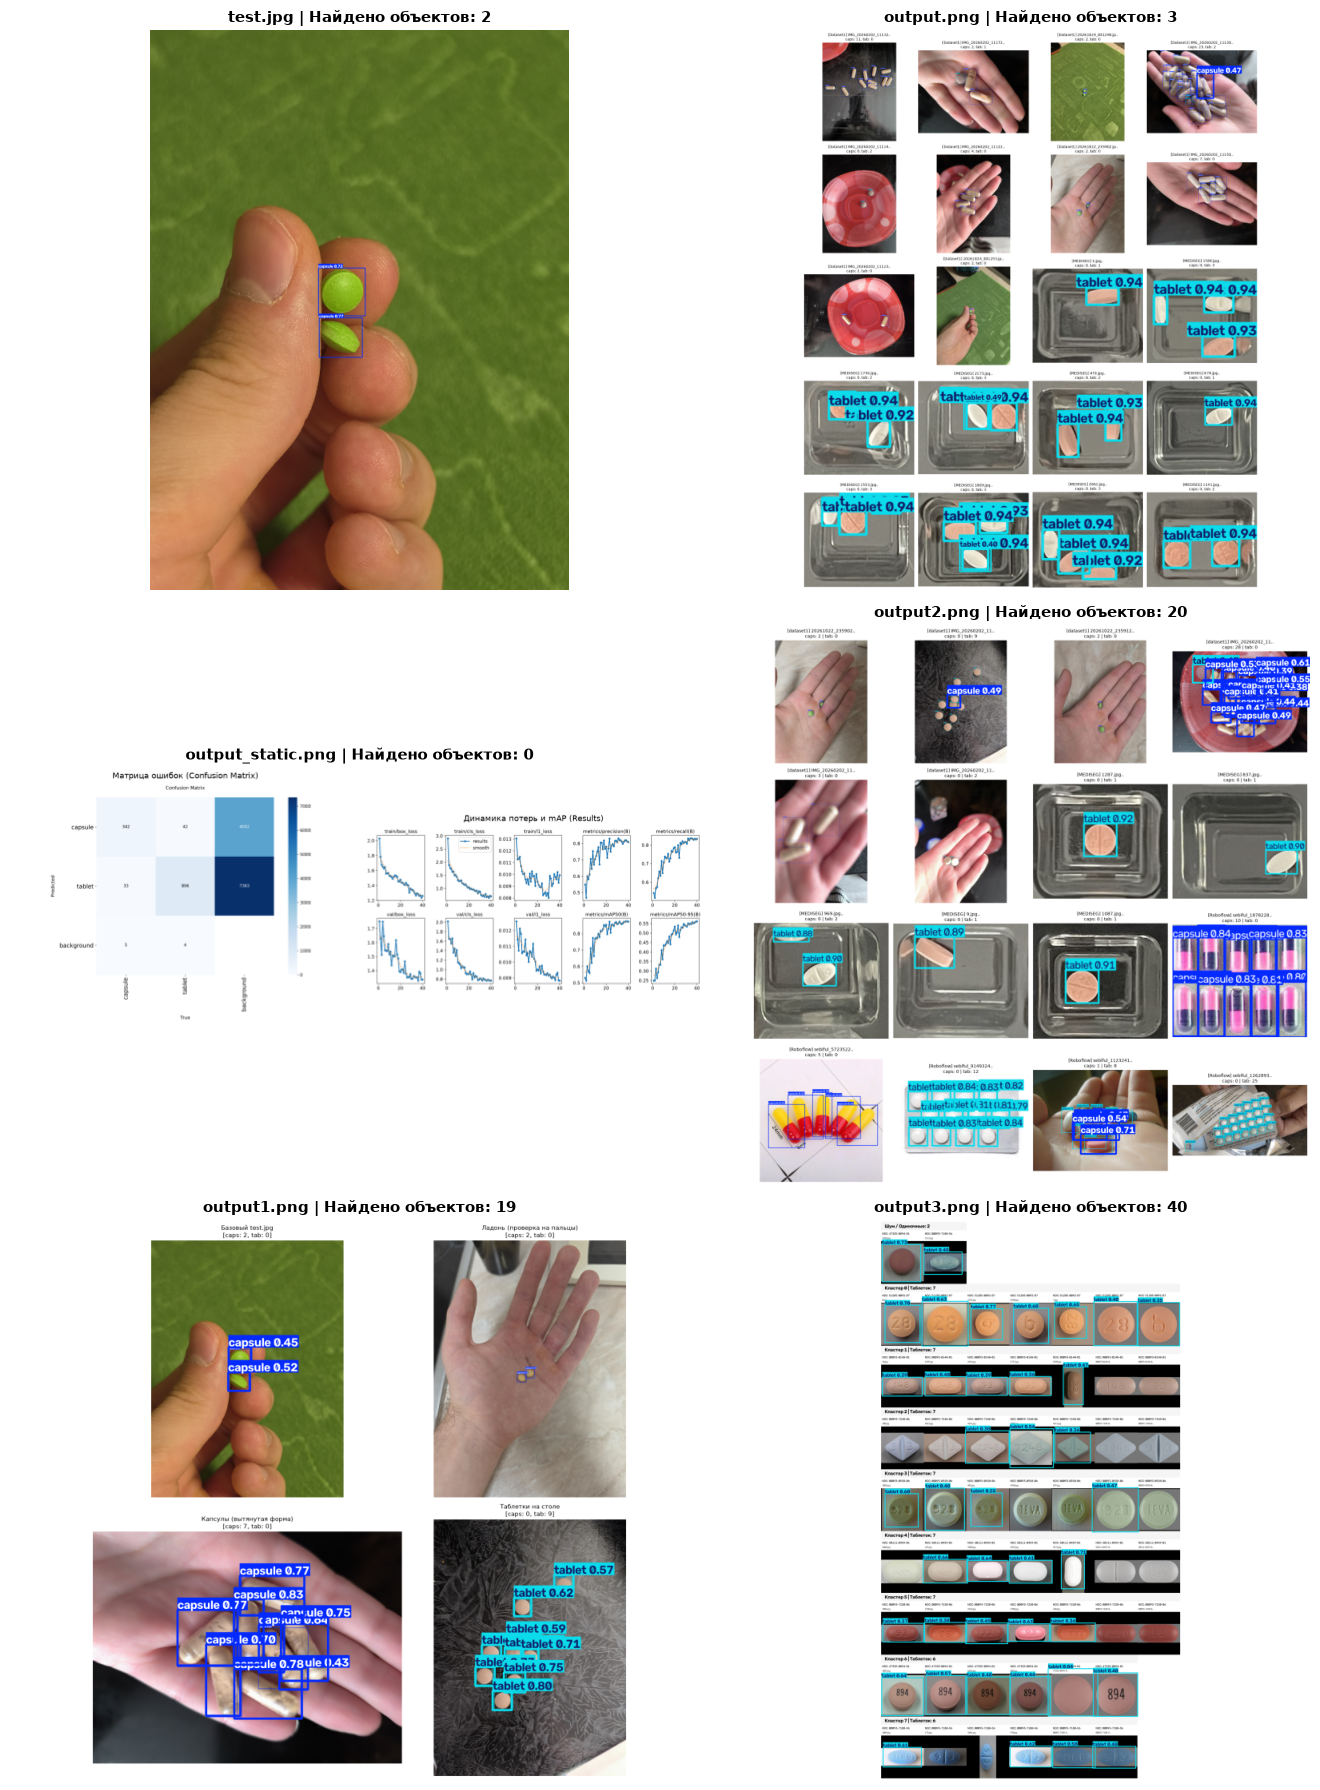

In [ ]:
# Папка со снимками
IMAGES_DIR = Path(r"D:\Tabmed\Datasets\dataset1\images")
if not IMAGES_DIR.exists():
    IMAGES_DIR = BASE_DIR

# Собираем все доступные фото
all_image_paths = sorted(
    list(IMAGES_DIR.glob("*.jpg")) + list(IMAGES_DIR.glob("*.png"))
)

# Выбираем для теста до 8 кадров
random.seed(42)
sample_paths = random.sample(all_image_paths, min(8, len(all_image_paths)))
print(f"Выбрано фото для пакетного анализа: {len(sample_paths)}")

# 1. Инференс детектора и сохранение результатов
batch_results = []
for p in sample_paths:
    res = yolo.predict(source=str(p), conf=0.35, verbose=False)[0]
    batch_results.append((p, res))

# 2. Отрисовка сетки кадров с боксами
n_imgs = len(batch_results)
cols = 2
rows = (n_imgs + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 6))
if rows == 1 and cols == 1:
    axes = np.array([axes])
axes = np.array(axes).flatten()

for idx, (p, res) in enumerate(batch_results):
    annotated = res.plot(line_width=3, font_size=1.0)
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    # Сжатие превью для плавного отображения без зависаний
    h, w = annotated_rgb.shape[:2]
    scale = 700 / max(h, w)
    preview = cv2.resize(
        annotated_rgb,
        (int(w * scale), int(h * scale)),
        interpolation=cv2.INTER_AREA,
    )

    n_det = len(res.boxes)
    axes[idx].imshow(preview)
    axes[idx].set_title(
        f"{p.name} | Найдено объектов: {n_det}", fontsize=11, fontweight="bold"
    )
    axes[idx].axis("off")

# Отключаем пустые слоты
for ax in axes[n_imgs:]:
    ax.axis("off")

plt.tight_layout()
plt.show()